# 情景导入
近几年，很多城市的房价波动较大，备受关注。房价的高低也是受多个因素影响的，如房子所处的城市是一线还是二线，房子周边交通方便程度如通不通地铁，房子周边有无学校和医院等，这些都影响了房子的价格。本实训案例通过周边犯罪率，房东收入，房间数，不动产税收率等指标预测美国城市波士顿的房价走向。

### [波士顿 房价回归数据集](https://scikit-learn.org/stable/datasets/toy_dataset.html#boston-dataset)

- 数据集来自卡内基梅隆大学维护的 StatLib 库。
- 样本包含 1970 年代的在波士顿郊区不同位置的房屋信息，总共有 13 种房屋属性。 目标值是**一个位置的房价的中值（单位：k$）**。
- 这十三个特征包括：
    1. 人均犯罪率
    1. 在25000平方英尺上住房的比例
    1. 每个镇上平均的非零售企业比例
    1. 是否沿河（查尔斯河）1/0
    1. 一氧化氮的浓度，单位是千万分之一
    1. 每个住所的平均房间数
    1. 1940年以前自己修的建筑比例
    1. 波士顿五个就业中心的加权距离
    1. 径向公路适应性指标
    1. 每10000的税率的完全价值
    1. 镇上的学生-老师比例
    1. 其中Bk是比例
    1. 低地位人口比例
- 而标签则是有房子人的房价的中位数。

# 实训步骤


## 步骤1 导入包
导入分别用于加载波士顿数据集、划分数据集、数据标准化、线性回归模型、均方误差评估、数据计算、画图需要的python包。


In [1]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error  
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei'] #显示中文标签

## 步骤2 获取数据
波士顿房价数据是比较经典的用于机器学习研究的数据集，被封装在sklearn数据集模块，可直接使用load_boston()函数加载使用。


In [2]:
#直接通过sklearn.datasets.fetch_openml函数来从openml.org下载数据集
#UserWarning: Multiple active versions of the dataset matching the name boston exist. Versions may be fundamentally different, returning version 1.
boston = fetch_openml(name="Boston", version=1, as_frame=True, parser='auto')

###  我们来看看数据长什么样子

In [3]:
boston.data

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48


In [4]:
# 特征名称
boston.feature_names

['CRIM',
 'ZN',
 'INDUS',
 'CHAS',
 'NOX',
 'RM',
 'AGE',
 'DIS',
 'RAD',
 'TAX',
 'PTRATIO',
 'B',
 'LSTAT']

In [ ]:
#目标值
boston.target

In [6]:
# 数据集大小
boston.data.shape


(506, 13)

## 步骤3 数据基本处理

In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(boston.data, boston.target, test_size=0.2)
print(x_train, x_train.shape)


        CRIM   ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  PTRATIO  \
358  5.20177  0.0  18.10    1  0.770  6.127  83.4  2.7227  24  666.0     20.2   
186  0.05602  0.0   2.46    0  0.488  7.831  53.6  3.1992   3  193.0     17.8   
105  0.13262  0.0   8.56    0  0.520  5.851  96.7  2.1069   5  384.0     20.9   
109  0.26363  0.0   8.56    0  0.520  6.229  91.2  2.5451   5  384.0     20.9   
36   0.09744  0.0   5.96    0  0.499  5.841  61.4  3.3779   5  279.0     19.2   
..       ...  ...    ...  ...    ...    ...   ...     ...  ..    ...      ...   
502  0.04527  0.0  11.93    0  0.573  6.120  76.7  2.2875   1  273.0     21.0   
70   0.08826  0.0  10.81    0  0.413  6.417   6.6  5.2873   4  305.0     19.2   
173  0.09178  0.0   4.05    0  0.510  6.416  84.1  2.6463   5  296.0     16.6   
164  2.24236  0.0  19.58    0  0.605  5.854  91.8  2.4220   5  403.0     14.7   
106  0.17120  0.0   8.56    0  0.520  5.836  91.9  2.2110   5  384.0     20.9   

          B  LSTAT  
358  3

In [8]:
#特征标准化 使用StandardScaler方法分别对训练集和测试集进行标准化。
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)


##  步骤4 构建线性回归模型
这里使用sklearn中的LinearRegression实现房价数据的回归拟合。首先构建一个LinearRegression实例，然后传入用于训练的输入和输出。

In [9]:
#实例化一个线性回归模型
exp = LinearRegression()
exp.fit(x_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.88, 0.86, 0.36,...,-2. , 0.95,-3. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.61
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](13,)","[49.95,24.03,22.54,..., 8.57, 8.14, 4.95]"


In [10]:
#得出模型
print("权重系数据W：\n", exp.coef_)
print("偏置：\n", exp.intercept_)

权重系数据W：
 [-0.88201376  0.86340742  0.35587017  0.4561879  -1.52635706  3.40653415
 -0.28691893 -2.53337767  2.04239779 -1.93415459 -2.00107588  0.95308371
 -3.00296126]
偏置：
 22.612871287128716


##  步骤5 线性回归模型评估
1. 输出模型在测试集上的预测值和准确率

2. 将测试集真实分布和的拟合曲线分别画出来

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
y_pred = exp.predict(x_test)
# ========== 计算均方误差MSE 和 R²决定系数 ==========
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("均方误差 MSE =", mse)
print("R² score =", r2)



均方误差 MSE = 37.51523846296918
R² score = 0.6148485901904495


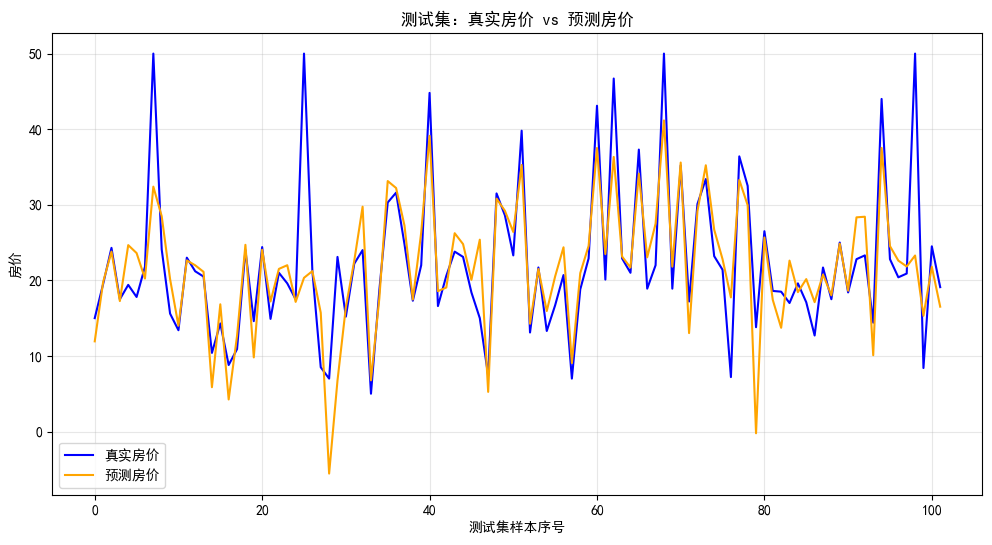

In [12]:
#以样本序号（1,2,3,4...）为横坐标，房价为纵坐标，将测试集真实房价和的预测房价两条曲线分别画出来
import matplotlib.pyplot as plt

# 生成样本序号作为x轴
sample_index = range(len(y_test))

plt.figure(figsize=(12,6))
plt.plot(sample_index, y_test, label='真实房价', color='blue')
plt.plot(sample_index, y_pred, label='预测房价', color='orange')

plt.xlabel("测试集样本序号")
plt.ylabel("房价")
plt.title("测试集：真实房价 vs 预测房价")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
import joblib  # 保存加载模型

# 保存模型：dump
joblib.dump(exp, 'bosten_linear_reg.pkl') # 导出
print('模型导出成功！')

# 加载模型：load 
import_lr = joblib.load('bosten_linear_reg.pkl') # 导入
import_lr

模型导出成功！


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.88, 0.86, 0.36,...,-2. , 0.95,-3. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.61
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](13,)","[49.95,24.03,22.54,..., 8.57, 8.14, 4.95]"


In [14]:
import os
print(os.path.abspath('.'))

D:\coding\JX


In [15]:
#使用模型
y_pre = import_lr.predict(x_test)
print("预测值是:\n", y_pre)
print(y_test == y_pre)
score = import_lr.score(x_test, y_test)
print("准确率是:\n", score)

# 用均方误差对回归模型评估
error =  mean_squared_error(y_test, y_pred)
print("均方误差MSE：\n", error)

预测值是:
 [11.92890282 19.75791873 23.79951847 17.26101898 24.6605734  23.60930979
 20.23703894 32.39905374 28.48292592 20.17020811 13.98840789 22.63665609
 21.99203602 21.1230119   5.86162956 16.8308731   4.23975179 12.65497804
 24.70010266  9.80436965 24.04257191 17.20049498 21.51258914 22.00171685
 17.14897371 20.33471128 21.22199765 15.71129043 -5.5648713   6.75260303
 16.45944484 22.57079126 29.74470264  6.77099871 17.63901538 33.13502626
 32.21782574 27.25869292 17.46563942 26.31890605 39.1157375  18.56789065
 19.05279828 26.23611012 24.79698583 20.0658807  25.37974008  5.24428433
 30.81394084 29.20214466 26.39854246 35.26934766 14.25925279 21.50346228
 15.93699596 20.52076503 24.3736916   9.05402401 20.95171731 24.56360051
 37.51024598 23.47988268 36.32889953 23.14684951 21.69997388 34.12112856
 23.03898433 27.49757863 41.15550476 21.81684975 35.58616592 13.01932452
 29.14342423 35.22388339 26.70829932 22.79646043 17.74457085 33.28598338
 29.94414687 -0.23210443 25.6699998  17.4146